# 🏁 Formula 1 Podium Prediction — Milestone 1

**Goal:** for each driver in each race, predict whether he finishes on the **podium** (top 3), using only information known **after qualifying and before the race starts**.

**Data:** Kaggle *Formula 1 World Championship (1950–2024)* — 14 linked CSV tables.

### Notebook map (checklist)

| Section | Checklist items |
|---|---|
| 1. Setup & loading | run-all ready |
| 2. EDA **before** cleaning | EDA + plots |
| 3. Cleaning | `\N` sentinels, semantic typing, PK/FK checks, one row per (raceId, driverId) |
| 4. EDA **after** cleaning | impact of cleaning, data-analysis plots |
| 5. Data-engineering questions Q1–Q3 | answers + plots + markdown |
| 6. Features | leakage-safe form features, evidence + plots for each feature |
| 7. Train / validation / test split | justified split |
| 8. Pre-processing | effect on distribution, 2 preprocessing-order experiments |

## 1. Setup & loading

We import the libraries, fix a random seed (so every run gives the same numbers), and find the data folder automatically (Kaggle mounts it under `/kaggle/input/...`).

We load every CSV **as text** (`dtype=str`) so we can see the raw values exactly as they are in the file, including the `\N` placeholders. The `raw` tables are never changed — all cleaning is done on a copy.

In [3]:
import os, sys, glob, warnings, subprocess
warnings.filterwarnings("ignore")
# for pkg in ["shap", "lime"]:
#     try: __import__(pkg)
#     except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
YEAR_MAX = 2024

DATA_DIR = "./dataset/archive"
print("Data folder:", DATA_DIR)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers", "driver_standings",
          "races", "results", "qualifying", "lap_times", "pit_stops", "sprint_results", "seasons", "status"]
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
pd.DataFrame({t: [len(df), df.shape[1]] for t, df in raw.items()}, index=["rows", "columns"]).T

Data folder: ./dataset/archive


,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


## 2. EDA before cleaning

### 2.1 Where are the missing values?
Ergast writes missing values as the text `\N`. We count them per column.

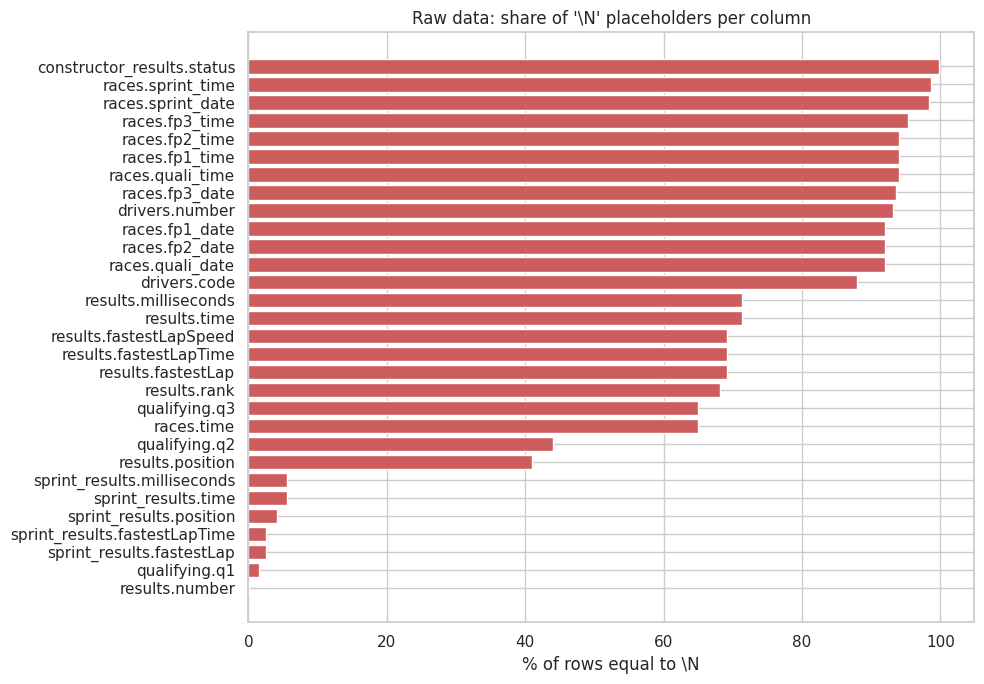

,column,pct_missing
0,constructor_results.status,99.9
13,races.sprint_time,98.7
12,races.sprint_date,98.4
9,races.fp3_time,95.3
7,races.fp2_time,94.0
5,races.fp1_time,94.0
11,races.quali_time,94.0
8,races.fp3_date,93.6
1,drivers.number,93.1
4,races.fp1_date,92.0


In [4]:
missing = []
for t, df in raw.items():
    for col in df.columns:
        share = (df[col] == "\\N").mean()
        if share > 0:
            missing.append({"column": f"{t}.{col}", "pct_missing": 100 * share})
missing = pd.DataFrame(missing).sort_values("pct_missing", ascending=False)

plt.figure(figsize=(10, 7))
plt.barh(missing.column, missing.pct_missing, color="indianred")
plt.gca().invert_yaxis(); plt.xlabel("% of rows equal to \\N")
plt.title("Raw data: share of '\\N' placeholders per column"); plt.tight_layout(); plt.show()
missing.head(10).round(1)

**What we see:** missing values are not random — they have a reason:
* `results.time`, `fastestLap…`: only finishers have a race time, and fastest-lap data only exists from 2004. These are **post-race** fields anyway, so we never use them as features.
* `results.position`: missing when the driver was not classified (crash, retirement). `positionOrder` is always filled, so we use it for the target.
* `qualifying.q2`, `q3`: drivers knocked out in Q1 have no Q2/Q3 time. So "missing" here means "eliminated early".
* `races.fp1_date …`: session times were only recorded for recent seasons.

### 2.2 Problem: numbers stored as text
If we load the files normally, any column that contains `\N` becomes a text column, so we cannot do maths on it.

In [5]:
naive = pd.read_csv(f"{DATA_DIR}/results.csv")
print("results columns loaded as text by a normal read:")
print([c for c in naive.columns if not pd.api.types.is_numeric_dtype(naive[c])])

results columns loaded as text by a normal read:
['number', 'position', 'positionText', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed']


### 2.3 How complete is the qualifying data over time?

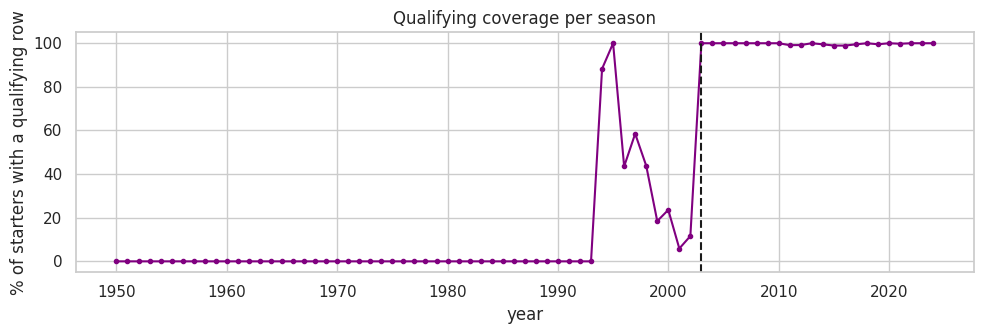

{1993: 0.0, 1994: 88.0, 1995: 100.0, 1996: 44.0, 1997: 59.0, 1998: 44.0, 1999: 18.0, 2000: 24.0, 2001: 6.0, 2002: 12.0, 2003: 100.0, 2004: 100.0}


In [6]:
years = raw["races"][["raceId", "year"]]
res_per_year = raw["results"].merge(years).year.astype(int).value_counts().sort_index()
q_per_year = raw["qualifying"].merge(years).year.astype(int).value_counts().reindex(res_per_year.index, fill_value=0)
coverage = (100 * q_per_year / res_per_year).loc[:YEAR_MAX]

coverage.plot(figsize=(10, 3.5), marker=".", color="purple")
plt.ylabel("% of starters with a qualifying row"); plt.title("Qualifying coverage per season")
plt.axvline(2003, ls="--", c="k"); plt.tight_layout(); plt.show()
print(coverage.loc[1993:2004].round(0).to_dict())

**Key finding:** qualifying data does not exist before 1994 and is very patchy between 1996 and 2002. It is complete only **from 2003**. That is why our **modeling table uses the seasons 2003–2024** (all features exist there). Older seasons are still used for the data-engineering questions and as *history* for the form features.

### 2.4 Duplicate driver–race rows

duplicated (raceId, driverId) rows: 176


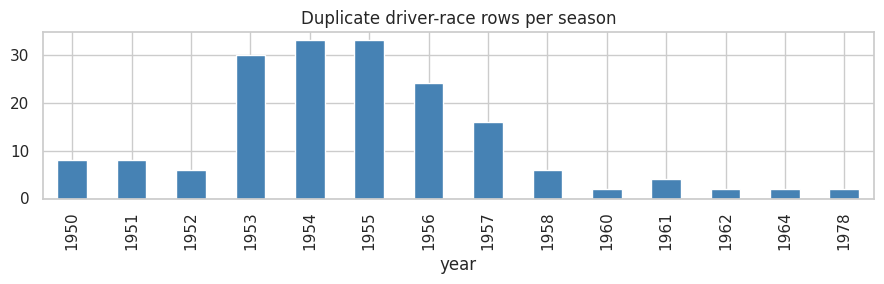

In [7]:
res_raw = raw["results"].merge(years)
dup = res_raw[res_raw.duplicated(["raceId", "driverId"], keep=False)]
print("duplicated (raceId, driverId) rows:", len(dup))
dup.year.astype(int).value_counts().sort_index().plot.bar(figsize=(9, 3), color="steelblue")
plt.title("Duplicate driver-race rows per season"); plt.tight_layout(); plt.show()

All duplicates are from the **1950s–60s "shared drives"**: a driver could take over a team-mate's car during the race, so he appears twice in the same race. We fix this in Section 3.

## 3. Data cleaning

### 3.1 Sentinels → real missing values
We replace every `\N` (and empty string) with a proper missing value `NaN`, on a **copy** of the data.

In [8]:
clean = {t: df.replace({"\\N": np.nan, "": np.nan}) for t, df in raw.items()}
print("remaining '\\N' cells:", sum(int((df == "\\N").sum().sum()) for df in clean.values()))

remaining '\N' cells: 0


### 3.2 Semantic typing
* **Numbers:** every column whose values are all numeric is converted to a number.
* **Dates:** `races.date` and `drivers.dob` become real dates.
* **Durations:** lap times like `"1:23.456"` become seconds (`83.456`). We check our converter against the `milliseconds` column that `lap_times` already has.

In [9]:
for t, df in clean.items():
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() == df[col].notna().sum():      # every non-missing value is a number
            df[col] = converted

clean["races"]["date"] = pd.to_datetime(clean["races"]["date"])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])

def to_seconds(value):
    """'83.4' -> 83.4 ; '1:23.456' -> 83.456 ; missing/invalid -> NaN"""
    if pd.isna(value): return np.nan
    try:
        seconds = 0.0
        for part in str(value).split(":"):
            seconds = seconds * 60 + float(part)
        return seconds
    except ValueError:
        return np.nan

for q in ["q1", "q2", "q3"]:
    clean["qualifying"][q + "_sec"] = clean["qualifying"][q].map(to_seconds)
clean["pit_stops"]["duration_sec"] = clean["pit_stops"]["duration"].map(to_seconds)
clean["lap_times"]["time_sec"] = clean["lap_times"]["time"].map(to_seconds)

err = (clean["lap_times"].time_sec * 1000 - clean["lap_times"].milliseconds).abs().max()
print(f"check: max difference between our seconds and the milliseconds column = {err:.1f} ms")
clean["qualifying"][["q1", "q1_sec", "q3", "q3_sec"]].dropna().head(3)

check: max difference between our seconds and the milliseconds column = 0.0 ms


,q1,q1_sec,q3,q3_sec
0,1:26.572,86.572,1:26.714,86.714
1,1:26.103,86.103,1:26.869,86.869
2,1:25.664,85.664,1:27.079,87.079


The difference is at most 1 ms (rounding), so the converter works.

### 3.3 Fixing inconsistent labels
`circuits.country` uses both `"USA"` and `"United States"`, and one nationality has a trailing space. We unify them, otherwise the home-race question (Q2) would be wrong.

In [10]:
# ── Audit: find all label inconsistencies before fixing them ──────────────

# 1. All distinct country names in circuits
print("circuits.country unique values:")
print(sorted(clean["circuits"]["country"].dropna().unique()), "\n")

# 2. All distinct nationality names in drivers
print("drivers.nationality unique values:")
print(sorted(clean["drivers"]["nationality"].dropna().unique()), "\n")

# 3. Nationality values that have leading/trailing whitespace
has_space = [n for n in clean["drivers"]["nationality"].dropna().unique() if n != n.strip()]
print("Nationality values with whitespace:", has_space or "none")

# 4. Cross-check: driver nationalities that imply a country name
#    but that country name doesn't appear in circuits at all
#    (catches word-form mismatches like Argentinian vs Argentina)
nat_to_country = {
    "American": "USA", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chinese": "China", "Dutch": "Netherlands", "Finnish": "Finland",
    "French": "France", "German": "Germany", "Hungarian": "Hungary",
    "Indian": "India", "Italian": "Italy", "Japanese": "Japan",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "Polish": "Poland", "Portuguese": "Portugal", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland",
}
circuit_countries = set(clean["circuits"]["country"].dropna().unique())
print("\nNationality → expected country   |  found in circuits?")
print("-" * 55)
for nat, country in sorted(nat_to_country.items()):
    found = country in circuit_countries
    flag = "✅" if found else "❌ MISSING"
    print(f"  {nat:<20} → {country:<18} {flag}")


circuits.country unique values:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States'] 

drivers.nationality unique values:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan'] 

Nati

In [ ]:
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})
clean["drivers"]["nationality"] = clean["drivers"]["nationality"].str.strip().replace({"Argentinian": "Argentine"})

### 3.4 Primary-key and foreign-key checks
* **Primary key (PK):** the column that identifies a row must be unique and never missing.
* **Foreign key (FK):** every ID that points to another table must exist in that table (otherwise joins silently lose rows).

In [ ]:
PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
      "status": ["statusId"], "results": ["resultId"], "qualifying": ["qualifyId"],
      "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
      "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"]}
pk_check = pd.DataFrame([{"table": t, "key": "+".join(k), "missing": int(clean[t][k].isna().any(axis=1).sum()),
                          "duplicates": int(clean[t].duplicated(k).sum())} for t, k in PK.items()])

FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
      ("races", "circuitId", "circuits"), ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
      ("constructor_standings", "raceId", "races"), ("lap_times", "raceId", "races"), ("pit_stops", "raceId", "races")]
fk_check = pd.DataFrame([{"foreign key": f"{child}.{col} -> {parent}",
                          "orphans": int((~clean[child][col].dropna().isin(clean[parent][col])).sum())} for child, col, parent in FK])
display(pk_check); display(fk_check)

All primary keys are unique and complete, and all foreign keys match (0 orphans), so joins are safe.

### 3.5 One row per (raceId, driverId)
**Rule:** for a shared drive we keep the row with the driver's **best finishing position** (`positionOrder`).
**Why:** the target asks "did this driver finish on the podium?", and the official record credits the driver with his best result. Keeping a random or the first row could give the wrong label.

We also remove entries that **never started** (did not qualify / did not pre-qualify / 107% rule): after qualifying we already know they will not race, so they are not real prediction cases.

In [ ]:
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
res = res[res.year <= YEAR_MAX]
before = len(res)
res = res.sort_values("positionOrder").drop_duplicates(["raceId", "driverId"], keep="first")
assert not res.duplicated(["raceId", "driverId"]).any()
print(f"rows: {before} -> {len(res)}  (removed {before - len(res)} duplicate rows)")

res["status"] = res.statusId.map(clean["status"].set_index("statusId").status)
res = res[~res.status.isin(["Did not qualify", "Did not prequalify", "107% Rule"])]
res["podium"] = (res.positionOrder <= 3).astype(int)
res["dnf"] = (~(res.status.eq("Finished") | res.status.str.startswith("+"))).astype(int)
print("race starters:", len(res), "| podium rate:", round(res.podium.mean(), 3))

## 4. EDA after cleaning

### 4.1 Impact of cleaning

In [ ]:
text_before = sum(not pd.api.types.is_numeric_dtype(naive[c]) for c in naive.columns)
text_after = sum(not pd.api.types.is_numeric_dtype(clean["results"][c]) for c in clean["results"].columns)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(["before", "after"], [text_before, text_after], color=["indianred", "seagreen"])
ax[0].set_title("results: text columns before / after typing")
ax[1].hist(clean["qualifying"].q1_sec.dropna(), bins=80, color="steelblue"); ax[1].set_yscale("log")
ax[1].set_title("Q1 lap time in seconds (now usable)")
ax[2].bar(["raw rows", "after dedup\n+ starters only"], [before, len(res)], color=["grey", "seagreen"])
ax[2].set_title("Rows before / after grain fix"); plt.tight_layout(); plt.show()

After cleaning, the numeric columns are real numbers, lap times can be compared, and each driver appears once per race. The Q1 histogram has several bumps because circuits have different lengths (60 s to 105 s) → we will use the **gap to the fastest driver in %**, not the raw time.

### 4.2 Building the master table (multi-table join)
`results` → `races` (year, date, circuit) → `circuits` (country) → `drivers` (birth date, nationality) → `constructors` (team name).

In [ ]:
races = clean["races"][["raceId", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
circuits = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
drivers = clean["drivers"][["driverId", "forename", "surname", "dob", "nationality"]]
teams = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "team"})

df = (res.merge(races, on="raceId").merge(circuits, on="circuitId")
         .merge(drivers, on="driverId").merge(teams, on="constructorId"))
assert len(df) == len(res)
df["driver"] = df.forename + " " + df.surname
df = df.sort_values(["date", "positionOrder"]).reset_index(drop=True)
df[["year", "race_name", "driver", "team", "grid", "positionOrder", "status", "podium"]].tail(3)

### 4.3 Class balance and the effect of the starting position

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df.podium.value_counts().plot.bar(ax=ax[0], color=["grey", "orange"]); ax[0].set_title(f"Podium = {df.podium.mean():.1%} of rows")
d = df[(df.year >= 2003) & df.grid.between(1, 20)]
d.groupby("grid").podium.mean().plot.bar(ax=ax[1], color="steelblue"); ax[1].set_title("P(podium) by grid position (2003-2024)")
df.groupby("year").dnf.mean().plot(ax=ax[2], color="indianred"); ax[2].set_title("DNF rate per season")
plt.tight_layout(); plt.show()

* Only ~13–14 % of rows are podiums → the classes are **imbalanced**. Accuracy would be misleading (always saying "no" gives 86 %), so we use **PR-AUC** as our main metric later.
* The grid position is the strongest signal: pole ≈ 70–80 % podium, P10 almost never. The curve is **not a straight line** → non-linear models should help.
* Cars got much more reliable (DNF rate fell from ~50 % to ~15 %).

## 5. Data-engineering questions

### Q1 — Which circuits convert a front-row start into a podium most often? Does it change after 2014?

**Tables joined:** `results` + `races` + `circuits` + `qualifying`.
**Front row** = starting position 1 or 2. We compute it two ways: by **grid** (where the car actually started, after penalties) and by **qualifying position** (before penalties).
**Period:** 2003–2024 (qualifying complete), split into **2003–2013** vs **2014–2024** (hybrid era). Circuits need at least 10 front-row starts in a period to be ranked.

In [ ]:
qual = clean["qualifying"].sort_values("position").drop_duplicates(["raceId", "driverId"])[["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]]
qual = qual.rename(columns={"position": "quali_pos"})
q1 = df[df.year >= 2003].merge(qual, on=["raceId", "driverId"], how="left")
q1["era"] = np.where(q1.year >= 2014, "2014-2024", "2003-2013")

def conversion(col):
    front = q1[q1[col].isin([1, 2])]
    t = front.groupby(["circuit", "era"]).podium.agg(rate="mean", starts="size").reset_index()
    return t[t.starts >= 10]

by_grid, by_quali = conversion("grid"), conversion("quali_pos")
print("Overall conversion by grid:", q1[q1.grid.isin([1, 2])].groupby("era").podium.mean().round(3).to_dict())
print("Overall conversion by qualifying:", q1[q1.quali_pos.isin([1, 2])].groupby("era").podium.mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, era in zip(ax, ["2003-2013", "2014-2024"]):
    top = by_grid[by_grid.era == era].sort_values("rate").tail(10)
    a.barh(top.circuit, top.rate, color="steelblue"); a.set_xlim(0, 1)
    a.set_title(f"Top 10 circuits: front row (grid) -> podium, {era}")
plt.tight_layout(); plt.show()

wide = by_grid.pivot(index="circuit", columns="era", values="rate").dropna()
rho = spearmanr(wide["2003-2013"], wide["2014-2024"])
print(f"Ranking similarity between eras (Spearman rho) = {rho.statistic:.2f}, p = {rho.pvalue:.2f}, circuits = {len(wide)}")
comp = by_grid.merge(by_quali, on=["circuit", "era"], suffixes=("_grid", "_quali"))
comp["difference"] = comp.rate_grid - comp.rate_quali
comp.sort_values("difference", key=abs, ascending=False).head(5).round(2)

**Answer Q1.**
* Front-row starters reached the podium **68 %** of the time in 2003–2013 and **76 %** in 2014–2024: the dominant hybrid-era teams (Mercedes, then Red Bull) converted front rows very reliably.
* The bar charts show the top 10 circuits in each era. The Spearman correlation between the two rankings is only **ρ ≈ 0.30 (p ≈ 0.29, 14 circuits)** — weak and not significant, so **the ranking changes after 2014**. Conversion depends more on the era's competitive order than on the track itself.
* **Grid vs qualifying:** by qualifying position the hybrid-era conversion is 73.7 % instead of 76 %. The table shows the circuits where the definitions differ most (e.g. Interlagos 2014–2024: 79 % by grid vs 65 % by qualifying). They differ because of grid penalties: a driver can qualify on the front row but start further back.
* *Grain:* one row per driver-race. *Missing values:* rows without a qualifying record are excluded only from the qualifying definition. *Cutoff:* grid and qualifying position are both known before the race.

### Q2 — Do drivers podium more often at home, after controlling for starting position?

**Tables joined:** `results` + `drivers` (nationality) + `races` + `circuits` (country). We map nationality → country (e.g. *British* → *UK*).
**Controlling for starting position:** we compare home and away drivers **inside the same grid bucket** (P1, P2–3, P4–6, …). Then we fit a logistic regression `podium ~ home + grid bucket + decade`. The coefficient of `home` is the home effect *at the same starting position*.

In [ ]:
NAT = {"British": "UK", "German": "Germany", "East German": "Germany", "Italian": "Italy", "French": "France",
       "Spanish": "Spain", "Brazilian": "Brazil", "American": "USA", "American-Italian": "USA", "Argentine": "Argentina",
       "Argentine-Italian": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
       "Canadian": "Canada", "Dutch": "Netherlands", "Finnish": "Finland", "Japanese": "Japan", "Mexican": "Mexico",
       "Monegasque": "Monaco", "Swiss": "Switzerland", "Swedish": "Sweden", "Russian": "Russia", "Portuguese": "Portugal",
       "South African": "South Africa", "Hungarian": "Hungary", "Chinese": "China", "Indian": "India",
       "Malaysian": "Malaysia", "Thai": "Thailand", "Danish": "Denmark", "New Zealander": "New Zealand"}
df["home_race"] = (df.nationality.map(NAT) == df.country).astype(int)

q2 = df[df.grid > 0].copy()
q2["grid_bucket"] = pd.cut(q2.grid, [0, 1, 3, 6, 10, 99], labels=["P1", "P2-3", "P4-6", "P7-10", "P11+"]).astype(str)
q2["decade"] = (q2.year // 10 * 10).astype(str)

rates = q2.groupby(["grid_bucket", "home_race"]).podium.mean().unstack()
rates.columns = ["away", "home"]
rates.plot.bar(figsize=(9, 4), color=["grey", "orange"], rot=0); plt.ylabel("podium rate")
plt.title("Podium rate: home vs away, same grid bucket"); plt.tight_layout(); plt.show()

model = smf.logit("podium ~ home_race + C(grid_bucket) + C(decade)", data=q2).fit(disp=0)
odds = np.exp(model.params["home_race"]); lo, hi = np.exp(model.conf_int().loc["home_race"])
print(f"Raw podium rate: home {q2[q2.home_race==1].podium.mean():.3f} vs away {q2[q2.home_race==0].podium.mean():.3f}")
print(f"Home odds ratio controlling for grid & decade = {odds:.2f}  (95% CI {lo:.2f}-{hi:.2f}, p = {model.pvalues['home_race']:.2f})")

**Answer Q2. No home advantage.** Without any control, home drivers actually podium *less* (11.5 % vs 13.8 %). Inside each grid bucket the home and away rates are similar. The controlled odds ratio is **0.92 (95 % CI 0.78–1.08, p ≈ 0.29)**: the interval contains 1, so after controlling for starting position there is **no evidence that racing at home helps**.
* *Grain:* driver-race starters with a grid slot (`grid > 0`). *Missing:* rows with `grid = 0` are excluded (no starting position to control for). *Cutoff:* nationality, circuit country and grid are all pre-race, so `home_race` is a legal feature.
* *Caution:* this is an association, not a cause. Nationality is only a rough proxy for "home".

### Q3 — Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?

**Tables joined:** `results` + `status` + `constructors` + `races`.
**Mechanical retirement** = the race ended because a car part failed. We list those statuses explicitly (engine, gearbox, brakes, hydraulics…). Crashes (*Accident, Collision, Spun off*), driver/medical reasons and regulation decisions (*Disqualified*) are **not** mechanical.
**Rate** = mechanical retirements ÷ race starts, per team and period (teams with at least 20 starts).

In [ ]:
MECHANICAL = {"Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
              "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Wheel", "Throttle",
              "Steering", "Technical", "Electronics", "Exhaust", "Oil leak", "Water leak", "Fuel pump", "Oil pressure",
              "Engine fire", "Pneumatics", "Wheel bearing", "Fuel system", "Power loss", "Vibrations", "Drivetrain", "Battery",
              "Turbo", "Water pump", "Power Unit", "ERS", "Cooling system", "Brake duct", "Undertray", "Fuel leak", "Oil line"}
q3 = df[df.year >= 2014].copy()
q3["period"] = np.where(q3.year <= 2021, "2014-2021", "2022-2024")
q3["mechanical"] = q3.status.isin(MECHANICAL).astype(int)
mech = q3.groupby(["period", "team"]).mechanical.agg(rate="mean", starts="size").reset_index()
mech = mech[mech.starts >= 20]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, p in zip(ax, ["2014-2021", "2022-2024"]):
    t = mech[mech.period == p].sort_values("rate")
    a.barh(t.team, t.rate, color="indianred"); a.axvline(q3[q3.period == p].mechanical.mean(), c="k", ls="--")
    a.set_title(f"Mechanical retirements per start, {p}")
plt.tight_layout(); plt.show()
print("Overall rate:", q3.groupby("period").mechanical.mean().round(3).to_dict())
for p in ["2014-2021", "2022-2024"]:
    print(p, "top 3:", mech[mech.period == p].nlargest(3, "rate")[["team", "rate", "starts"]].round(3).values.tolist())

**Answer Q3.**
* **2014–2021** (average 9.5 % of starts): highest rates for **Caterham (23.5 %)**, **Lotus F1 (17.1 %)** and **Toro Rosso (16.1 %)**, followed by McLaren in its Honda years.
* **2022–2024** (average 6.0 %, cars became more reliable): highest for **Alfa Romeo (12.5 %)**, **Alpine (11.0 %)** and **AlphaTauri (8.0 %)**.
* With only ~60–140 starts per team in 2022–2024, small differences between teams are not significant.
* *Grain:* one row per driver-race start. *Cutoff:* `status` is **post-race** information, so this is only a descriptive analysis — it is never used as a feature.

## 6. Feature engineering

### 6.1 Which fields would be leakage?
**Leakage** = using information that is only known *after* the race starts. Allowed vs. not allowed:

| ❌ Not allowed (future) | ✅ Allowed (known before the start) |
|---|---|
| `positionOrder`, `position`, `points`, `laps`, `time`, `fastestLap`, `status` of **this** race | `grid`, qualifying position and lap times |
| lap times / pit stops of **this** race | results of **previous** races (form) |
| standings **after** this race (`driver_standings` with this raceId) | standings after the **previous** round |
| | driver age, nationality, circuit, team |

### 6.2 Our features (6 groups)

| Group | Feature | Meaning |
|---|---|---|
| grid | `grid` | starting slot (pit-lane start = back of the grid) |
| grid | `pitlane_start` | 1 if the car started from the pit lane |
| qualifying | `quali_pos` | qualifying position |
| qualifying | `quali_gap_pct` | gap to the fastest qualifier, in % |
| driver form | `drv_podiums_last5` | share of podiums in the driver's previous 5 races |
| driver form | `drv_avg_finish_last5` | average finishing position in previous 5 races |
| team form | `team_podiums_last5` | average podiums per race for the team, previous 5 races |
| standings | `drv_points_share` | driver's points ÷ leader's points before this race |
| standings | `drv_champ_pos` | driver's championship position before this race |
| standings | `team_champ_pos` | team's championship position before this race |
| context | `driver_age` | age on race day |
| context | `home_race` | 1 if the race is in the driver's country |

**Leakage-safe form features:** we sort each driver's races by date and use `shift(1)` **before** the rolling average. `shift(1)` moves everything down one race, so the value for a race only uses races **before** it.

In [ ]:
df = df.sort_values(["date", "raceId"]).reset_index(drop=True)
df["field_size"] = df.groupby("raceId").driverId.transform("size")

# grid
df["pitlane_start"] = (df.grid == 0).astype(int)
df["grid_feat"] = np.where(df.grid > 0, df.grid, df.field_size)

# qualifying
qual["best_q"] = qual[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
qual["quali_gap_pct"] = (100 * (qual.best_q / qual.groupby("raceId").best_q.transform("min") - 1)).clip(upper=10)
df = df.merge(qual[["raceId", "driverId", "quali_pos", "quali_gap_pct"]], on=["raceId", "driverId"], how="left")

# driver form: only PAST races (shift(1) then rolling)
by_driver = df.groupby("driverId")
df["drv_podiums_last5"] = by_driver.podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df["drv_avg_finish_last5"] = by_driver.positionOrder.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# team form: podiums per race for the team, then shift(1) + rolling over the team's past races
team_race = df.groupby(["constructorId", "raceId", "date"], as_index=False).podium.sum().sort_values("date")
team_race["team_podiums_last5"] = team_race.groupby("constructorId").podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df = df.merge(team_race[["constructorId", "raceId", "team_podiums_last5"]], on=["constructorId", "raceId"], how="left")

# standings after the PREVIOUS round of the same season
rr = clean["races"][["raceId", "year", "round"]]
prev = rr.assign(round=rr["round"] + 1).rename(columns={"raceId": "prev_raceId"})
df = df.merge(prev, on=["year", "round"], how="left")
ds = clean["driver_standings"][["raceId", "driverId", "points", "position"]].rename(columns={"raceId": "prev_raceId", "points": "drv_pts", "position": "drv_champ_pos"})
ds["leader_pts"] = ds.groupby("prev_raceId").drv_pts.transform("max")
cs = clean["constructor_standings"][["raceId", "constructorId", "position"]].rename(columns={"raceId": "prev_raceId", "position": "team_champ_pos"})
df = df.merge(ds, on=["prev_raceId", "driverId"], how="left").merge(cs, on=["prev_raceId", "constructorId"], how="left")
df["drv_points_share"] = (df.drv_pts / df.leader_pts.replace(0, np.nan)).fillna(0)

# context
df["driver_age"] = (df.date - df.dob).dt.days / 365.25

GROUPS = {"grid": ["grid_feat", "pitlane_start"], "qualifying": ["quali_pos", "quali_gap_pct"],
          "driver_form": ["drv_podiums_last5", "drv_avg_finish_last5"], "team_form": ["team_podiums_last5"],
          "standings": ["drv_points_share", "drv_champ_pos", "team_champ_pos"], "context": ["driver_age", "home_race"]}
FEATURES = [f for g in GROUPS.values() for f in g]
print(len(FEATURES), "features:", FEATURES)

### 6.3 Test: does the form feature really use only past races?
For 100 random rows we recompute `drv_podiums_last5` by hand, using only races with an **earlier date**, and check that it matches.

In [ ]:
mismatches = 0
for _, row in df[df.year >= 2003].sample(100, random_state=SEED).iterrows():
    past = df[(df.driverId == row.driverId) & (df.date < row.date)].sort_values("date")
    expected = past.podium.tail(5).mean() if len(past) else np.nan
    if not (np.isclose(expected, row.drv_podiums_last5) or (np.isnan(expected) and np.isnan(row.drv_podiums_last5))):
        mismatches += 1
print("mismatches:", mismatches)
assert mismatches == 0

### 6.4 Modeling table
We keep the seasons **2003–2024** (complete qualifying, see 2.3). The form features were computed on the full history, so a driver in 2003 already has his past results.

In [ ]:
data = df[df.year >= 2003].reset_index(drop=True)
assert not data.duplicated(["raceId", "driverId"]).any()
print(f"Modeling table: {len(data)} rows (one per driver per race), podium rate {data.podium.mean():.3f}")
data[FEATURES].isna().mean().round(3).to_frame("missing share").T

Few values are missing: rookies have no form yet, and at round 1 there are no standings yet. We fill them in Section 8.

### 6.5 Evidence for each feature
We use **only the training seasons** (2003–2017) so that we do not peek at the test data.
1. **Univariate ROC-AUC:** how well the feature alone ranks podium vs non-podium (0.5 = useless, 1 = perfect).
2. **Podium rate per feature bin:** shows the shape of the relationship.
3. **Correlation between features:** finds redundant features.

In [ ]:
train_part = data[data.year <= 2017]
def single_auc(col):
    x, y = train_part[col], train_part.podium
    ok = x.notna(); a = roc_auc_score(y[ok], x[ok]); return max(a, 1 - a)
auc_table = pd.Series({f: single_auc(f) for f in FEATURES}).sort_values()
auc_table.plot.barh(figsize=(8, 5), color="seagreen"); plt.axvline(0.5, c="k")
plt.title("Each feature alone: ROC-AUC (training seasons)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, f in zip(axes, ["grid_feat", "quali_gap_pct", "drv_podiums_last5", "team_podiums_last5",
                        "drv_points_share", "team_champ_pos", "driver_age", "home_race"]):
    bins = train_part[f] if train_part[f].nunique() <= 6 else pd.qcut(train_part[f], 8, duplicates="drop")
    train_part.groupby(bins, observed=True).podium.mean().plot(ax=ax, marker="o")
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60, labelsize=7)
plt.suptitle("Podium rate per feature bin (training seasons)"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6.5))
sns.heatmap(train_part[FEATURES].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f")
plt.title("Correlation between features"); plt.tight_layout(); plt.show()

**Why each feature is kept:**
* **grid / qualifying:** strongest signals (AUC ≈ 0.9). The podium rate drops very fast with worse grid or a bigger gap to pole.
* **form & standings:** strong (AUC ≈ 0.8–0.85). They tell us *how good the car is*: a fast car that starts P8 after a penalty still has a chance.
* **context:** weak. `driver_age` peaks in the early 30s; `home_race` shows almost no effect (matches Q2). We keep them because they are cheap and the ablation will test them.
* **Correlations:** grid and qualifying position are strongly correlated (most drivers start where they qualified). We keep both because penalties make them different, and our ablation measures what each adds.

**Leakage check:** to show what leakage looks like, we compute the AUC of `points` from the **same** race — it is almost perfect. That is exactly why it is not allowed.

In [ ]:
print("AUC of 'points' of the same race (forbidden):", round(single_auc("points"), 3))
print("AUC of 'grid' (allowed):", round(single_auc("grid_feat"), 3))

## 7. Train / validation / test split

We split by **season** (time), not randomly:

| Split | Seasons | Used for |
|---|---|---|
| Train | 2003–2017 | fitting the models |
| Validation | 2018–2021 | choosing hyperparameters and the decision threshold |
| Test | 2022–2024 | final evaluation, used **once** |

**Why by time?** The model will be used to predict *future* races, so we must test it on races that come after the training data. A random split would put races from the same season (or even the same race) in train and test, which makes the score look better than it really is. 2022 also starts new car rules, so the test set is a fair "unseen future" check.

In [ ]:
train = data[data.year <= 2017]; val = data[(data.year >= 2018) & (data.year <= 2021)]; test = data[data.year >= 2022]
X_train, y_train = train[FEATURES], train.podium.values
X_val, y_val = val[FEATURES], val.podium.values
X_test, y_test = test[FEATURES], test.podium.values
pd.DataFrame({"rows": [len(train), len(val), len(test)], "podium rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(3)

## 8. Pre-processing

1. **Imputation:** fill missing values with the **median** of the training data (median is robust to skewed features).
2. **Scaling:** `StandardScaler` → each feature has mean 0 and standard deviation 1. Logistic regression and the neural network need this; the random forest does not.

Both are **fit on the training set only**, then applied to validation and test.

In [ ]:
imputer = SimpleImputer(strategy="median").fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))
def prep(X, scale=True):
    Z = imputer.transform(X)
    return scaler.transform(Z) if scale else Z

Xtr_imp, Xva_imp, Xte_imp = prep(X_train, False), prep(X_val, False), prep(X_test, False)
Xtr_sc, Xva_sc, Xte_sc = prep(X_train), prep(X_val), prep(X_test)

fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, f in enumerate(["grid_feat", "quali_gap_pct", "driver_age"]):
    i = FEATURES.index(f)
    ax[0, j].hist(X_train[f].dropna(), bins=30, color="grey"); ax[0, j].set_title(f"{f} — raw")
    ax[1, j].hist(Xtr_sc[:, i], bins=30, color="steelblue"); ax[1, j].set_title(f"{f} — imputed + scaled")
plt.tight_layout(); plt.show()
pd.DataFrame({"raw mean": X_train.mean(), "raw std": X_train.std(), "after mean": Xtr_sc.mean(0), "after std": Xtr_sc.std(0)},
             index=FEATURES).round(2)

**Effect:** the shape of each distribution stays the same; only the scale changes (all features now have mean 0, std 1 and no missing values). Imputation adds a small spike at the median for features that had missing values.

### 8.1 Pre-processing-order experiments
We keep the model fixed (logistic regression) and change only the **order** of pre-processing steps:
* **Experiment 1 — fit the scaler/imputer before vs after splitting.** "Before" = fit on *all* data, including test (a common mistake: test information leaks into training).
* **Experiment 2 — impute then scale vs scale then impute.**

In [ ]:
def lr_score(Xtr, Xva, Xte):
    m = LogisticRegression(max_iter=2000).fit(Xtr, y_train)
    return {"val PR-AUC": average_precision_score(y_val, m.predict_proba(Xva)[:, 1]),
            "test PR-AUC": average_precision_score(y_test, m.predict_proba(Xte)[:, 1])}

rows = {}
# correct: fit on train only (already done above)
rows["E1: fit on train only (correct)"] = lr_score(Xtr_sc, Xva_sc, Xte_sc)
# wrong: fit on everything before splitting
all_X = pd.concat([X_train, X_val, X_test])
imp_all = SimpleImputer(strategy="median").fit(all_X); sc_all = StandardScaler().fit(imp_all.transform(all_X))
f_all = lambda X: sc_all.transform(imp_all.transform(X))
rows["E1: fit on ALL data before split (leaky)"] = lr_score(f_all(X_train), f_all(X_val), f_all(X_test))
# order: scale first, then impute
sc_first = StandardScaler().fit(X_train)                     # StandardScaler ignores NaN when fitting
imp_after = SimpleImputer(strategy="median").fit(sc_first.transform(X_train))
f_si = lambda X: imp_after.transform(sc_first.transform(X))
rows["E2: impute -> scale"] = rows["E1: fit on train only (correct)"]
rows["E2: scale -> impute"] = lr_score(f_si(X_train), f_si(X_val), f_si(X_test))
pd.DataFrame(rows).T.round(4)

**Result** (PR-AUC differs only in the 4th decimal):
* **Experiment 1:** the scores are almost the same, because the medians and means barely change with more data. But the "fit on all data" version is still **wrong**: it uses test-set statistics during training, which is impossible in real use. We keep "fit on train only".
* **Experiment 2:** both orders give nearly identical results. We keep the standard order **impute → scale**, so the scaler sees complete data.